#**1. Observar o Panorama Geral**



Configuração inicial do setup para o notebook.

In [ ]:
import sys
from packaging import version
import sklearn

# garantia da versão do python
assert sys.version_info >= (3, 7)

# garantia da versão do sklearn
assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

In [ ]:
# Definição de fontes padrão para os gráficos
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

**Dataset:** MNIST, que é um conjunto de 70.000 imagens pequenas de dígitos escritos à mão por estudantes do ensino médio e funcionários do Censo dos EUA.

**Objetivo:** Reconhecer qual dígito foi escrito à mão.

**Tipo de Aprendizado:** Aprendizado Supervisionado

**Tipo de Tarefa:** Classificação Multiclasse

**Quantidade de entradas e saídas:** SISO

**Formato de aprendizado:** Aprendizado em lote

**Medida de Desempenho:** Acurácia, Precisão, Recall, Matriz Confusão, Curva ROC


# **2. Obtenção dos Dados**

In [ ]:
# Importar o dataset MINIST
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', as_frame=False)

mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

## **2.1. Observação dos Primeiros Dados**

In [ ]:
# os dados em si de entrada e saída são representados por esses atributos
X, y = mnist.data, mnist.target

In [ ]:
# X representa a imagem 28 x 28
print(X)
print(X.shape)

# y representa o label dessa imagem
print(y)
print(y.shape)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
(70000, 784)
['5' '0' '4' ... '4' '5' '6']
(70000,)


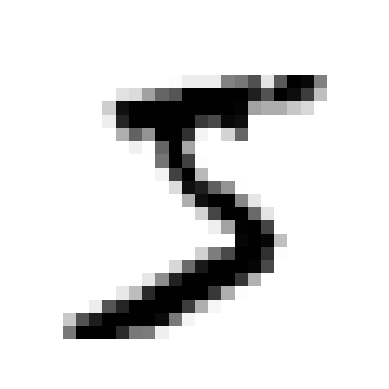

5


In [ ]:
# Representação dos Dados
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

index = 0   # escolha o índice do dataset para mostrar

some_digit = X[index]
plot_digit(some_digit)
plt.show()

# label
print(y[index])

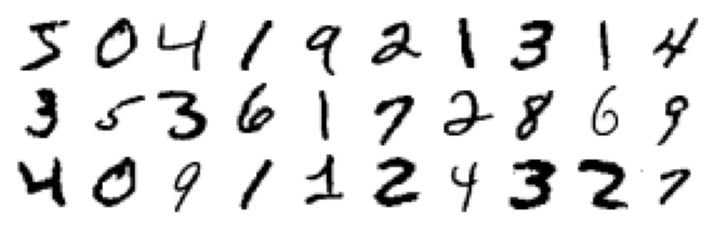

In [ ]:
import math

def plot_digits_grid(X, num_digits=100):
    # Calcula colunas (máximo 10) e linhas necessárias dinamicamente
    cols = min(10, num_digits) # até 10 colunas
    rows = math.ceil(num_digits / cols) # calcula o numero de linhas necessárias

    plt.figure(figsize=(cols * 0.9, rows * 0.9)) # redimensiona o tamanho da figura

    # loop para plotar cada dígito
    for idx, image_data in enumerate(X[:num_digits]):
        plt.subplot(rows, cols, idx + 1)
        plot_digit(image_data)

    plt.subplots_adjust(wspace=0, hspace=0)
    plt.show()

# quantidade de dígitos
num_digits = 30
plot_digits_grid(X, num_digits)

## **2.2. Descrição dos Dados**

In [ ]:
import numpy as np
import pandas as pd

# Converter o array para Pandas
serie = pd.Series(y)

# 2. Usar to_numeric para forçar a conversão. O que não for número vira NaN (Not a Number)
serie_numerica = pd.to_numeric(serie, errors='coerce')

# 3. Agora pode Pandas para checar por nulos
contagem_nulos = serie_numerica.isnull().sum()
print(f"Quantidade de dados nulos (NaN): {contagem_nulos}")

# Mostra quantidade absoluta e relativa lado a lado
distribuicao = pd.DataFrame({
    'Quantidade': serie_numerica.value_counts(dropna=False),
    'Porcentagem': serie_numerica.value_counts(normalize=True, dropna=False).map('{:.2%}'.format)
})
print("\nDistribuição Detalhada das Categorias:")
print(distribuicao)

Quantidade de dados nulos (NaN): 0

Distribuição Detalhada das Categorias:
   Quantidade Porcentagem
1        7877      11.25%
7        7293      10.42%
3        7141      10.20%
2        6990       9.99%
9        6958       9.94%
0        6903       9.86%
6        6876       9.82%
8        6825       9.75%
4        6824       9.75%
5        6313       9.02%


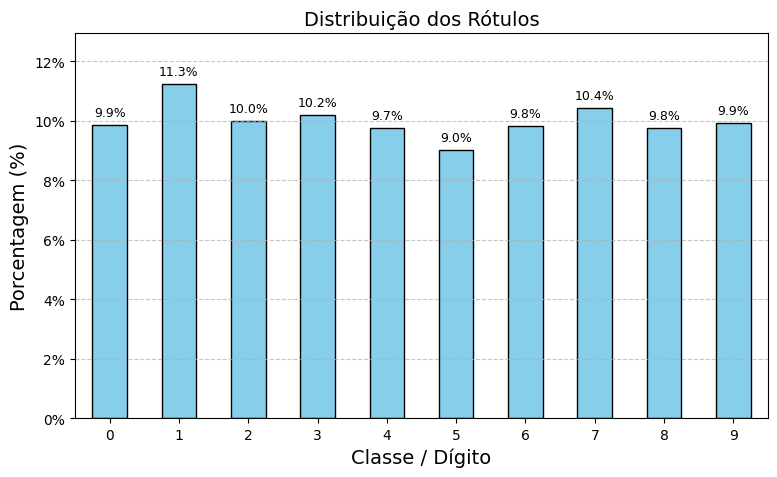

In [ ]:
import matplotlib.ticker as mtick

# 1. Calcula as frequências relativas
proporcoes = serie_numerica.value_counts(normalize=True).sort_index()

plt.figure(figsize=(8, 5))
ax = proporcoes.plot(kind='bar', color='skyblue', edgecolor='black')

# 2. Formata o eixo Y para mostrar % (ex: 10.0%)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# 3. Adiciona o valor em porcentagem no topo de cada barra
for i, valor in enumerate(proporcoes):
    ax.text(
        i,
        valor + 0.002,             # Posição vertical um pouco acima da barra
        f"{valor:.1%}",            # Formatação em porcentagem com 1 casa decimal
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title("Distribuição dos Rótulos")
plt.xlabel("Classe / Dígito")
plt.ylabel("Porcentagem (%)")
plt.xticks(rotation=0)
plt.ylim(0, max(proporcoes) * 1.15)  # Dá um espaço extra no topo para o texto não cortar
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## **2.3. Separação dos Dados de Treino e Teste**

In [ ]:
from sklearn.model_selection import train_test_split

# Divisão COM Estratificação
X_train, X_test, y_train, y_test = train_test_split(
   X, y, test_size=0.2, stratify=y, random_state=42)

serie_Strat_Treino = pd.Series(y_train)
serie_Strat_Teste = pd.Series(y_test)

print("Distribuição das categorias no Conjunto de Treino:")
print(serie_Strat_Treino.value_counts(normalize=True).map('{:.2%}'.format))

print("\nDistribuição das categorias no Conjunto de Teste:")
print(serie_Strat_Teste.value_counts(normalize=True).map('{:.2%}'.format))

print("\n--- Usando train_test_split para Divisão ---")
print(f"Formato do conjunto de treino: {X_train.shape}")
print(f"Formato do conjunto de teste: {X_test.shape}")

Distribuição das categorias no Conjunto de Treino:
1    11.25%
7    10.42%
3    10.20%
2     9.99%
9     9.94%
0     9.86%
6     9.82%
8     9.75%
4     9.75%
5     9.02%
Name: proportion, dtype: object

Distribuição das categorias no Conjunto de Teste:
1    11.25%
7    10.42%
3    10.20%
2     9.99%
9     9.94%
0     9.86%
6     9.82%
8     9.75%
4     9.75%
5     9.02%
Name: proportion, dtype: object

--- Usando train_test_split para Divisão ---
Formato do conjunto de treino: (56000, 784)
Formato do conjunto de teste: (14000, 784)


# **3. Classificação Multiclasse**

A classificação multiclasse lida com problemas onde há três ou mais classes possíveis, mas cada instância de dado pertence a exatamente uma única classe.

Em relação a esse tipo de classificação, há duas categorias de modelos:

* **Modelos Nativos:** Algoritmos como Regressão Logística, Random Forest, Naive Bayes e Softmax Regression conseguem lidar com múltiplas classes.

* **Modelos Estritamente Binários:** Algoritmos como o classificador linear por Gradiente Descendente Estocástico (SGDClassifier) e as Máquinas de Vetores de Suporte (SVC) são, por definição matemática, projetados para decidir entre apenas duas opções.

Estratégias para usar Classificadores Binários em Tarefas Multiclasse:

*   **Um-contra-o-Resto (OvR):** Para N classes, treina-se N classificadores. Cada um aprende a distinguir uma classe específica de todas as outras juntas (ex: "é 7?" ou "não é 7?"). A classe final é aquela cujo classificador deu a maior pontuação de confiança. A estratégia OvR é geralmente preferida para a maioria dos outros algoritmos.

*  **Um-contra-Um (OvO):** Para N classes, treina-se um classificador para cada par de classes (total de N * (N-1) / 2 classificadores). Para classificar uma nova imagem, ela passa por todos os "duelos" e a classe que vencer mais vezes é a escolhida. A estratégia OvO é melhor para algoritmos que são lentos com grandes volumes de dados (como SVMs), pois cada classificador é treinado em um subconjunto menor dos dados.

## **3.1 SGDClassifier**

Usa internamente a abordagem OvR, ou seja, treina 10 classificadores binários, um para cada dígito. Precisa-se padronizar os dados usando o StandardScaler.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Padronizar os pixels do MNIST para melhorar o SGD, já que variam de 0 a 255
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [ ]:
#  Classificador Binário Descida de Gradiente Estocástico
from sklearn.linear_model import SGDClassifier

print("Treinando o SGD Classifier...")
sgd_clf = SGDClassifier(class_weight='balanced',max_iter=1000, tol=1e-3, random_state=42)
sgd_clf.fit(X_train_scaled, y_train)
print("Treinamento concluído com sucesso!\n")

Treinando o SGD Classifier...
Treinamento concluído com sucesso!



In [ ]:
# Avaliando a Pontuação
indice_amostra = 8
amostra = X_train_scaled[indice_amostra : indice_amostra + 1]
rotulo_real = y_train[indice_amostra]

# O método decision_function retorna 10 pontuações (uma por classe)
scores = sgd_clf.decision_function(amostra)[0]
digito_predito = np.argmax(scores)

print("=" * 60)
print(f"ANÁLISE DE PONTUAÇÕES NA AMOSTRA DE TREINO #{indice_amostra}")
print("=" * 60)
print(f"Rótulo Real:     {rotulo_real}")
print(f"Dígito Predito:  {digito_predito}")
print(f"Maior Score:     {scores[digito_predito]:.2f}\n")

print("Pontuações calculadas para cada classificador binário (0 a 9):")
for digito, score in enumerate(scores):
    marcador = " <--- (Escolhido)" if digito == digito_predito else ""
    print(f"  Dígito {digito}: {score:10.2f}{marcador}")

ANÁLISE DE PONTUAÇÕES NA AMOSTRA DE TREINO #8
Rótulo Real:     2
Dígito Predito:  2
Maior Score:     196.55

Pontuações calculadas para cada classificador binário (0 a 9):
  Dígito 0:   -1311.85
  Dígito 1:    -303.83
  Dígito 2:     196.55 <--- (Escolhido)
  Dígito 3:    -518.99
  Dígito 4:   -1134.51
  Dígito 5:    -637.74
  Dígito 6:    -254.80
  Dígito 7:   -1588.22
  Dígito 8:    -218.15
  Dígito 9:   -1434.25


## **3.2. DummyClassifier**

Considerou-se dois tipos de dummyclassifier para o treinamento.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

print("Treinando o Dummy Classifier do tipo Most_frequent...")
# 1. Dummy com estratégia de classe mais frequente
dummy_most_frequent = DummyClassifier(strategy="most_frequent")
dummy_most_frequent.fit(X_train, y_train)

print("Treinando o Dummy Classifier do tipo Uniforme...")
# 2. Dummy com chute totalmente uniforme/aleatório
dummy_uniform = DummyClassifier(strategy="uniform", random_state=42)
dummy_uniform.fit(X_train, y_train)

print("Treinamento concluído com sucesso!\n")

Treinando o Dummy Classifier do tipo Most_frequent...
Treinando o Dummy Classifier do tipo Uniforme...
Treinamento concluído com sucesso!



## **3.3. RandomForest**

A Floresta Aleatória calcula a proporção de árvores que votaram em cada classe, retornando probabilidades estimadas via `predict_proba()` (a soma das 10 saídas é sempre igual a 1 ou 100%).

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# n_estimators=100: cria 100 árvores de decisão na floresta
# n_jobs=-1: usa todos os núcleos do processador para acelerar
forest_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

print("Treinando a Random Forest no conjunto de treino...")
forest_clf.fit(X_train, y_train)
print("Treinamento concluído com sucesso!\n")

Treinando a Random Forest no conjunto de treino...
Treinamento concluído com sucesso!



In [ ]:
indice_amostra = 1
amostra = X_train[indice_amostra : indice_amostra + 1]
rotulo_real = y_train[indice_amostra]

# predict_proba retorna um array de tamanho 10 com valores de 0.0 a 1.0 (soma = 1.0)
probas = forest_clf.predict_proba(amostra)[0]
digito_predito = np.argmax(probas)

print("=" * 60)
print(f"ANÁLISE DE PROBABILIDADES NA AMOSTRA DE TREINO #{indice_amostra}")
print("=" * 60)
print(f"Rótulo Real:        {rotulo_real}")
print(f"Dígito Escolhido:   {digito_predito}")
print(f"Certeza do Modelo:  {probas[digito_predito]:.2%}\n")

print("Votação percentual das 100 árvores para cada dígito (0 a 9):")
for digito, prob in enumerate(probas):
    marcador = " <--- (Predição Final)" if digito == digito_predito else ""
    print(f"  Dígito {digito}: {prob:6.2%}{marcador}")

ANÁLISE DE PROBABILIDADES NA AMOSTRA DE TREINO #1
Rótulo Real:        7
Dígito Escolhido:   7
Certeza do Modelo:  94.00%

Votação percentual das 100 árvores para cada dígito (0 a 9):
  Dígito 0:  0.00%
  Dígito 1:  1.00%
  Dígito 2:  1.00%
  Dígito 3:  0.00%
  Dígito 4:  0.00%
  Dígito 5:  1.00%
  Dígito 6:  1.00%
  Dígito 7: 94.00% <--- (Predição Final)
  Dígito 8:  0.00%
  Dígito 9:  2.00%


## **3.4. Support Vector Classifier**

Ao contrário do SGD (que usa OvR e treina 10 modelos), o SVC treina um classificador binário para cada par de dígitos possível. Dessa forma, o total de classificadores treinados internamente é:

$$\frac{N \times (N - 1)}{2} = \frac{10 \times 9}{2} = 45 \text{ modelos binários}$$

A imagem passa pelos 45 classificadores e o dígito que vencer mais duelos diretos é o vencedor final (votação por maioria).

Além disso, assim como o SGD, o SVC necessita da padronização dos dados.

In [ ]:
from sklearn.svm import SVC

# kernel='rbf': Mapeia os dados para um espaço de dimensão superior não linear
# gamma='scale': Ajusta automaticamente o alcance da influência de cada amostra
svc_clf = SVC(kernel='rbf', gamma='scale', random_state=42)

print("Treinando o SVC no conjunto de treino (padronizado)...")
svc_clf.fit(X_train_scaled, y_train)
print("Treinamento concluído com sucesso!\n")

Treinando o SVC no conjunto de treino (padronizado)...
Treinamento concluído com sucesso!



In [ ]:
indice_amostra = 1
amostra = X_train_scaled[indice_amostra : indice_amostra + 1]
rotulo_real = y_train[indice_amostra]

# No SVC multiclasse, decision_function retorna 10 scores agregados (um por dígito)
scores_svc = svc_clf.decision_function(amostra)[0]
digito_predito = np.argmax(scores_svc)

print("=" * 60)
print(f"ANÁLISE DE PONTUAÇÕES DO SVC NA AMOSTRA DE TREINO #{indice_amostra}")
print("=" * 60)
print(f"Rótulo Real:        {rotulo_real}")
print(f"Dígito Escolhido:   {digito_predito}")
print(f"Total de Modelos Binários Internos (OvO): {len(svc_clf.estimators_ if hasattr(svc_clf, 'estimators_') else []) or 45}\n")

print("Pontuações agregadas para cada dígito (0 a 9):")
for digito, score in enumerate(scores_svc):
    marcador = " <--- (Vencedor dos Duelos)" if digito == digito_predito else ""
    print(f"  Dígito {digito}: {score:8.2f}{marcador}")

ANÁLISE DE PONTUAÇÕES DO SVC NA AMOSTRA DE TREINO #1
Rótulo Real:        7
Dígito Escolhido:   7
Total de Modelos Binários Internos (OvO): 45

Pontuações agregadas para cada dígito (0 a 9):
  Dígito 0:     0.69
  Dígito 1:     6.24
  Dígito 2:     3.88
  Dígito 3:     5.09
  Dígito 4:     2.73
  Dígito 5:     1.70
  Dígito 6:    -0.31
  Dígito 7:     9.32 <--- (Vencedor dos Duelos)
  Dígito 8:     7.30
  Dígito 9:     8.30


# **4. Avaliação de Performance**

## **4.1 SGDClassifier**

In [ ]:
from sklearn.model_selection import cross_validate

# Lista de métricas ajustadas para o contexto MULTICLASSE
metricas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

# Executa a validação cruzada
resultados_sgd = cross_validate(
    sgd_clf,
    X_train_scaled,
    y_train,
    cv=3,
    scoring=metricas,
    n_jobs=-1
)

# 3. Exibe as médias das métricas
print("=== DESEMPENHO DO SGD NA VALIDAÇÃO CRUZADA (TREINO) ===")
print(f"Acurácia:   {resultados_sgd['test_accuracy'].mean():.2%}")
print(f"Precisão:   {resultados_sgd['test_precision_macro'].mean():.2%}")
print(f"Recall:     {resultados_sgd['test_recall_macro'].mean():.2%}")
print(f"F1-Score:   {resultados_sgd['test_f1_macro'].mean():.2%}")

=== DESEMPENHO DO SGD NA VALIDAÇÃO CRUZADA (TREINO) ===
Acurácia:   90.03%
Precisão:   90.84%
Recall:     89.91%
F1-Score:   90.12%


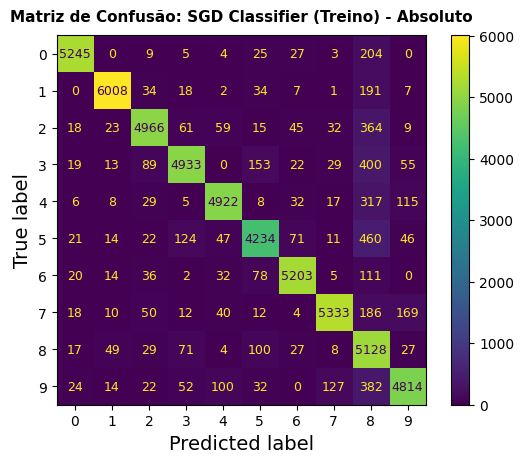

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred_sgd = sgd_clf.predict(X_train_scaled)

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_sgd)

plt.title("Matriz de Confusão: SGD Classifier (Treino) - Absoluto", fontsize=11, fontweight='bold', pad=10)

plt.show()

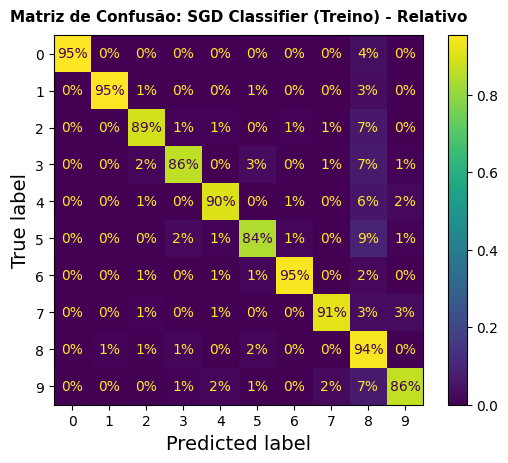

In [ ]:
plt.rc('font', size=10)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_sgd,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: SGD Classifier (Treino) - Relativo", fontsize=11, fontweight='bold', pad=10)

plt.show()

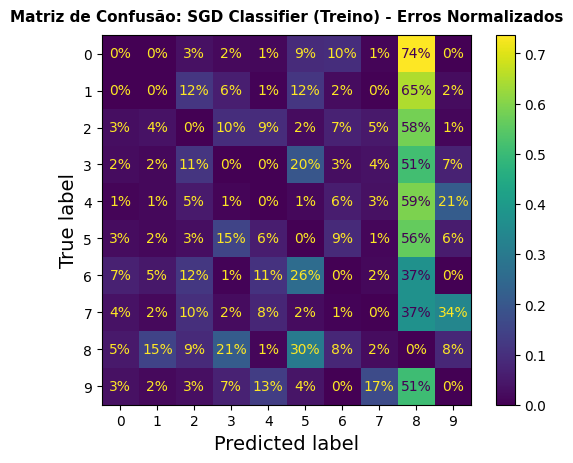

In [ ]:
# destque para os erros normalizados
sample_weight = (y_train_pred_sgd != y_train)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_sgd,
sample_weight=sample_weight,
normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: SGD Classifier (Treino) - Erros Normalizados", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **4.2. DummyClasifier**

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

# Executa a Validação Cruzada (3 folds) nos dados de TREINO
resultados_dummy = cross_validate(
    dummy_most_frequent,
    X_train,        # O Dummy não precisa dos dados padronizados
    y_train,
    cv=3,
    scoring=metricas,
    n_jobs=-1
)

# 4. Exibe as médias das métricas
print("=== DESEMPENHO DO DUMMY CLASSIFIER (CV - TREINO) ===")
print(f"Acurácia:   {resultados_dummy['test_accuracy'].mean():.2%}")
print(f"Precisão:   {resultados_dummy['test_precision_macro'].mean():.2%}")
print(f"Recall:     {resultados_dummy['test_recall_macro'].mean():.2%}")
print(f"F1-Score:   {resultados_dummy['test_f1_macro'].mean():.2%}")

=== DESEMPENHO DO DUMMY CLASSIFIER (CV - TREINO) ===
Acurácia:   11.25%
Precisão:   1.13%
Recall:     10.00%
F1-Score:   2.02%


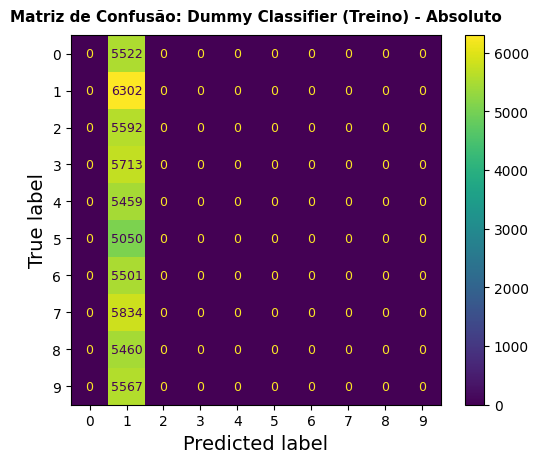

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred_dummy = dummy_most_frequent.predict(X_train)

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_dummy)

plt.title("Matriz de Confusão: Dummy Classifier (Treino) - Absoluto", fontsize=11, fontweight='bold', pad=10)

plt.show()

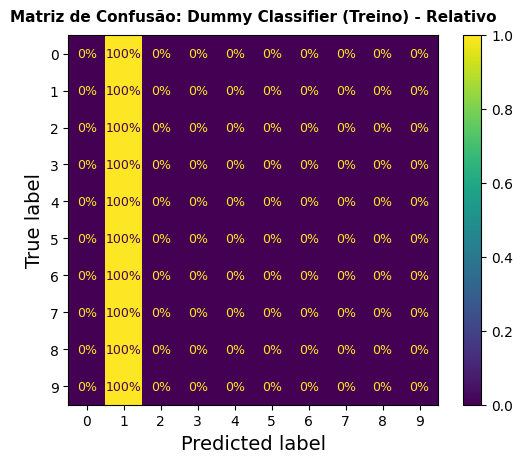

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_dummy,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Dummy Classifier (Treino) - Relativo", fontsize=11, fontweight='bold', pad=10)

plt.show()

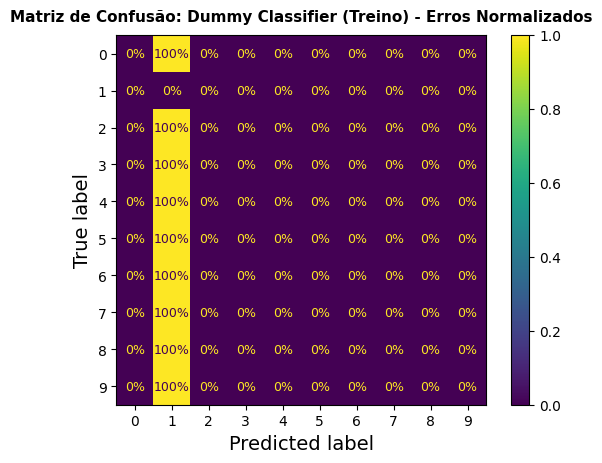

In [ ]:
# destque para os erros normalizados
sample_weight = (y_train_pred_dummy != y_train)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_dummy,
sample_weight=sample_weight,
normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Dummy Classifier (Treino) - Erros Normalizados", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **4.3. RandomForest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

# Executa a Validação Cruzada (3 folds) nos dados de TREINO
resultados_forest = cross_validate(
    forest_clf,
    X_train,        # Dados originais sem escala
    y_train,
    cv=3,
    scoring=metricas,
    n_jobs=-1
)

# Exibe as médias das métricas
print("=== DESEMPENHO DA RANDOM FOREST (CV - TREINO) ===")
print(f"Acurácia:   {resultados_forest['test_accuracy'].mean():.2%}")
print(f"Precisão:   {resultados_forest['test_precision_macro'].mean():.2%}")
print(f"Recall:     {resultados_forest['test_recall_macro'].mean():.2%}")
print(f"F1-Score:   {resultados_forest['test_f1_macro'].mean():.2%}")

=== DESEMPENHO DA RANDOM FOREST (CV - TREINO) ===
Acurácia:   96.54%
Precisão:   96.51%
Recall:     96.51%
F1-Score:   96.51%


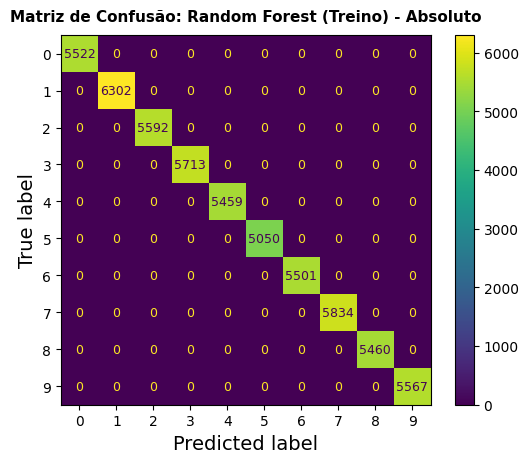

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred_forest = forest_clf.predict(X_train)

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_forest)

plt.title("Matriz de Confusão: Random Forest (Treino) - Absoluto", fontsize=11, fontweight='bold', pad=10)

plt.show()

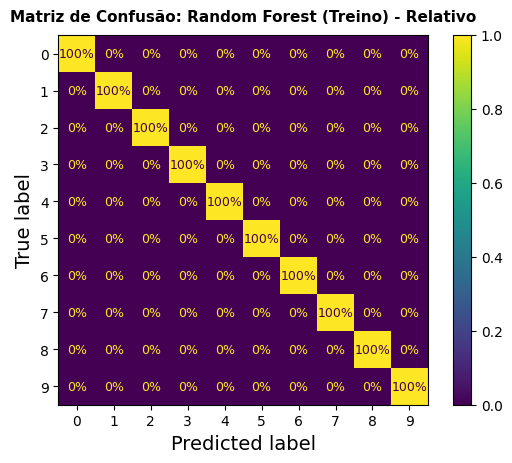

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_forest,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Random Forest (Treino) - Relativo", fontsize=11, fontweight='bold', pad=10)

plt.show()

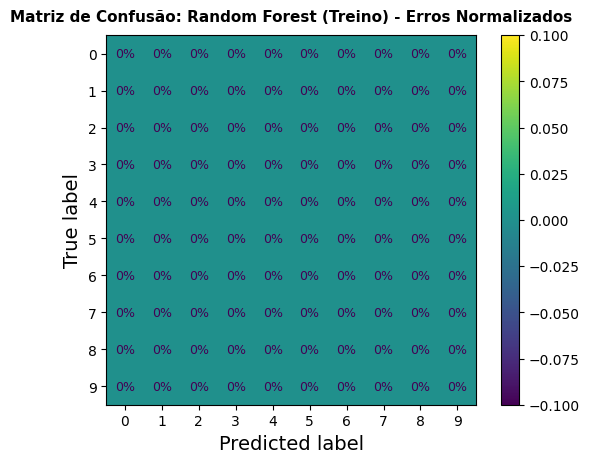

In [ ]:
# destque para os erros normalizados
sample_weight = (y_train_pred_forest != y_train)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_forest,
sample_weight=sample_weight,
normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Random Forest (Treino) - Erros Normalizados", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **4.4. SVC**

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.svm import SVC

# Executa a Validação Cruzada (3 folds) nos dados de TREINO PADRONIZADOS
resultados_svc = cross_validate(
    svc_clf,
    X_train_scaled,  # Obrigatório uso dos dados padronizados
    y_train,
    cv=3,
    scoring=metricas,
    n_jobs=-1,
)

# Exibe as médias das métricas
print("=== DESEMPENHO DO SVC (CV - TREINO) ===")
print(f"Acurácia:   {resultados_svc['test_accuracy'].mean():.2%}")
print(f"Precisão:   {resultados_svc['test_precision_macro'].mean():.2%}")
print(f"Recall:     {resultados_svc['test_recall_macro'].mean():.2%}")
print(f"F1-Score:   {resultados_svc['test_f1_macro'].mean():.2%}")

=== DESEMPENHO DO SVC (CV - TREINO) ===
Acurácia:   96.01%
Precisão:   96.04%
Recall:     95.97%
F1-Score:   95.99%


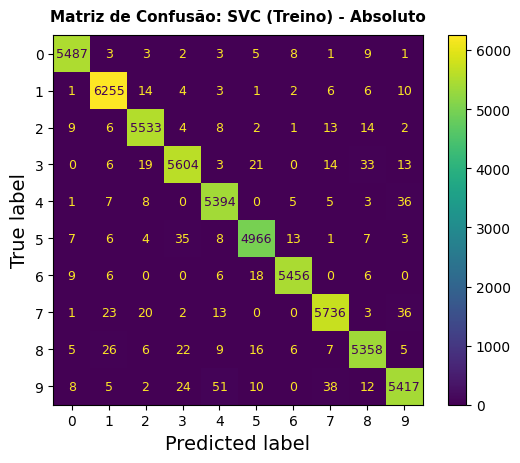

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred_svc = svc_clf.predict(X_train_scaled)

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_svc)

plt.title("Matriz de Confusão: SVC (Treino) - Absoluto", fontsize=11, fontweight='bold', pad=10)

plt.show()

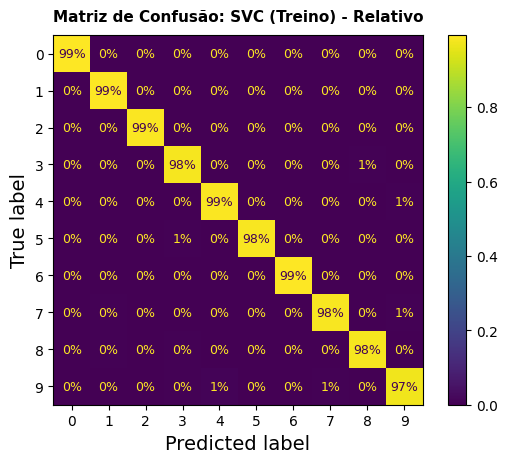

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.rc('font', size=9)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_svc,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: SVC (Treino) - Relativo", fontsize=11, fontweight='bold', pad=10)

plt.show()

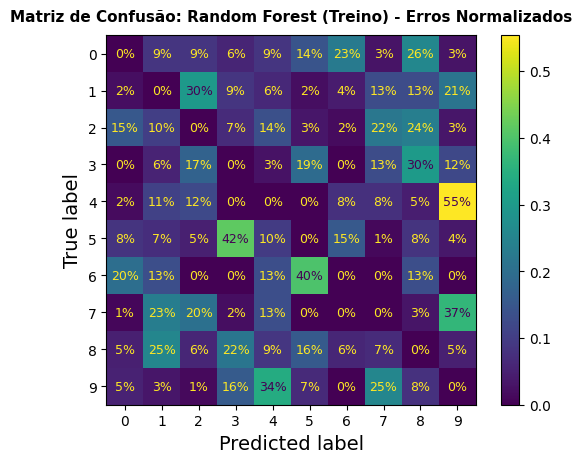

In [ ]:
# destque para os erros normalizados
sample_weight = (y_train_pred_svc != y_train)

ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred_svc,
sample_weight=sample_weight,
normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Random Forest (Treino) - Erros Normalizados", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **4.5. Gráfico Resumo**

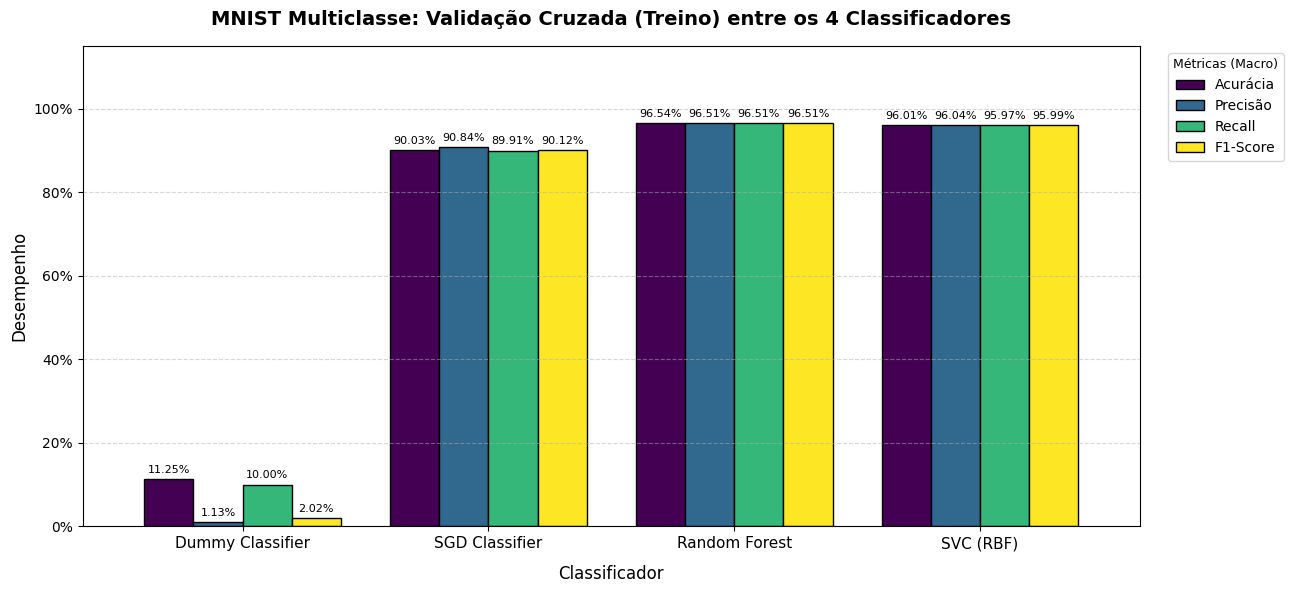

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

# Estrutura de dados com os resultados de cada cross_validate (incluindo o SVC)
dados_comparativos = {
    'Modelo': [
        'Dummy Classifier',
        'SGD Classifier',
        'Random Forest',
        'SVC (RBF)',
    ],
    'Acurácia': [
        resultados_dummy['test_accuracy'].mean(),
        resultados_sgd['test_accuracy'].mean(),
        resultados_forest['test_accuracy'].mean(),
        resultados_svc['test_accuracy'].mean(),
    ],
    'Precisão': [
        resultados_dummy['test_precision_macro'].mean(),
        resultados_sgd['test_precision_macro'].mean(),
        resultados_forest['test_precision_macro'].mean(),
        resultados_svc['test_precision_macro'].mean(),
    ],
    'Recall': [
        resultados_dummy['test_recall_macro'].mean(),
        resultados_sgd['test_recall_macro'].mean(),
        resultados_forest['test_recall_macro'].mean(),
        resultados_svc['test_recall_macro'].mean(),
    ],
    'F1-Score': [
        resultados_dummy['test_f1_macro'].mean(),
        resultados_sgd['test_f1_macro'].mean(),
        resultados_forest['test_f1_macro'].mean(),
        resultados_svc['test_f1_macro'].mean(),
    ],
}

# Converte para DataFrame
df_comparacao = pd.DataFrame(dados_comparativos)

# Configura o tamanho da figura
fig, ax = plt.subplots(figsize=(13, 6))

# Plota o gráfico de barras diretamente do DataFrame
df_comparacao.set_index('Modelo').plot(
    kind='bar',
    ax=ax,
    width=0.8,
    colormap='viridis',
    edgecolor='black',
)

# Estilização do gráfico
plt.title(
    'MNIST Multiclasse: Validação Cruzada (Treino) entre os 4 Classificadores',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Classificador', fontsize=12, labelpad=10)
plt.ylabel('Desempenho', fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.ylim(0, 1.15)  # Espaço no topo para os rótulos numéricos

# Formata o eixo Y para mostrar porcentagem (ex: 80%)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(
    title='Métricas (Macro)',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=10,
)

# Adiciona os valores em porcentagem no topo das barras
for container in ax.containers:
  labels = [f'{v * 100:.2f}%' for v in container.datavalues]
  ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=0)

plt.tight_layout()
plt.show()

# **5. Teste**

## **5.1. SGDClassifier**

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

X_test_scaled = scaler.transform(X_test)

print("\n" + "="*40)
print("     TESTE: SGD CLASSIFIER")
print("="*40)

# Predição (Usa dados padronizados X_test_scaled)
y_pred_sgd = sgd_clf.predict(X_test_scaled)

# Métricas detalhadas por classe (0 a 9)
print(classification_report(y_test, y_pred_sgd, digits=4))

# Resumo com agregação macro para multiclasse
print("-" * 40)
print(f"Acurácia:   {accuracy_score(y_test, y_pred_sgd):.2%}")
print(f"Precisão:   {precision_score(y_test, y_pred_sgd, average='macro', zero_division=0):.2%}")
print(f"Recall:     {recall_score(y_test, y_pred_sgd, average='macro'):.2%}")
print(f"F1-Score:   {f1_score(y_test, y_pred_sgd, average='macro'):.2%}")
print("-" * 40)


     TESTE: SGD CLASSIFIER
              precision    recall  f1-score   support

           0     0.9652    0.9450    0.9550      1381
           1     0.9760    0.9543    0.9650      1575
           2     0.9404    0.8698    0.9038      1398
           3     0.9220    0.8613    0.8907      1428
           4     0.9391    0.8806    0.9089      1365
           5     0.8952    0.8250    0.8587      1263
           6     0.9479    0.9404    0.9441      1375
           7     0.9448    0.9157    0.9300      1459
           8     0.6508    0.9392    0.7688      1365
           9     0.9123    0.8454    0.8776      1391

    accuracy                         0.8989     14000
   macro avg     0.9094    0.8977    0.9003     14000
weighted avg     0.9110    0.8989    0.9017     14000

----------------------------------------
Acurácia:   89.89%
Precisão:   90.94%
Recall:     89.77%
F1-Score:   90.03%
----------------------------------------


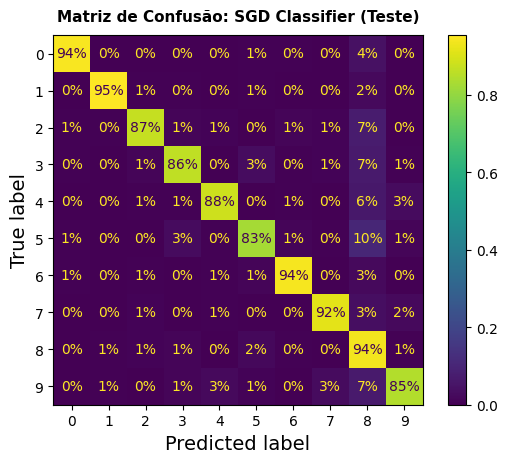

In [ ]:
plt.rc('font', size=10)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_sgd,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: SGD Classifier (Teste)", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **5.2. DummyClassifier**

In [ ]:
print("\n" + "="*40)
print("     TESTE: Dummy CLASSIFIER")
print("="*40)

# Predição
y_pred_dummy = dummy_most_frequent.predict(X_test)

# Métricas detalhadas por classe (0 a 9)
print(classification_report(y_test, y_pred_dummy, digits=4))

# Resumo com agregação macro para multiclasse
print("-" * 40)
print(f"Acurácia:   {accuracy_score(y_test, y_pred_dummy):.2%}")
print(f"Precisão:   {precision_score(y_test, y_pred_dummy, average='macro', zero_division=0):.2%}")
print(f"Recall:     {recall_score(y_test, y_pred_dummy, average='macro'):.2%}")
print(f"F1-Score:   {f1_score(y_test, y_pred_dummy, average='macro'):.2%}")
print("-" * 40)


     TESTE: Dummy CLASSIFIER
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000      1381
           1     0.1125    1.0000    0.2022      1575
           2     0.0000    0.0000    0.0000      1398
           3     0.0000    0.0000    0.0000      1428
           4     0.0000    0.0000    0.0000      1365
           5     0.0000    0.0000    0.0000      1263
           6     0.0000    0.0000    0.0000      1375
           7     0.0000    0.0000    0.0000      1459
           8     0.0000    0.0000    0.0000      1365
           9     0.0000    0.0000    0.0000      1391

    accuracy                         0.1125     14000
   macro avg     0.0112    0.1000    0.0202     14000
weighted avg     0.0127    0.1125    0.0228     14000

----------------------------------------
Acurácia:   11.25%


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Precisão:   1.12%
Recall:     10.00%
F1-Score:   2.02%
----------------------------------------


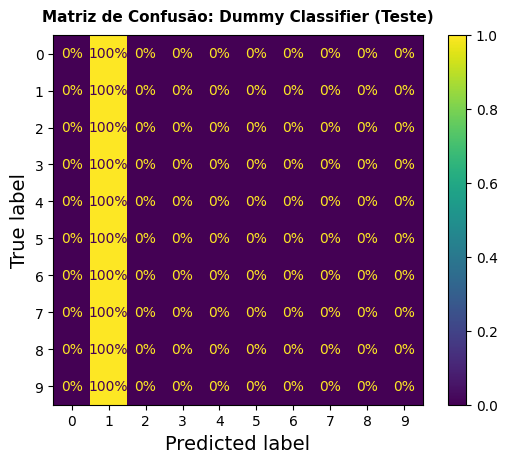

In [ ]:
plt.rc('font', size=10)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dummy,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Dummy Classifier (Teste)", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **5.3. Random Forest**

In [ ]:
print("\n" + "="*40)
print("     TESTE: Random Forest")
print("="*40)

# Predição
y_pred_forest = forest_clf.predict(X_test)

# Métricas detalhadas por classe (0 a 9)
print(classification_report(y_test, y_pred_forest, digits=4))

# Resumo com agregação macro para multiclasse
print("-" * 40)
print(f"Acurácia:   {accuracy_score(y_test, y_pred_forest):.2%}")
print(f"Precisão:   {precision_score(y_test, y_pred_forest, average='macro', zero_division=0):.2%}")
print(f"Recall:     {recall_score(y_test, y_pred_forest, average='macro'):.2%}")
print(f"F1-Score:   {f1_score(y_test, y_pred_forest, average='macro'):.2%}")
print("-" * 40)


     TESTE: Random Forest
              precision    recall  f1-score   support

           0     0.9710    0.9928    0.9817      1381
           1     0.9847    0.9829    0.9838      1575
           2     0.9650    0.9657    0.9653      1398
           3     0.9647    0.9580    0.9613      1428
           4     0.9676    0.9612    0.9644      1365
           5     0.9718    0.9557    0.9637      1263
           6     0.9726    0.9818    0.9772      1375
           7     0.9692    0.9692    0.9692      1459
           8     0.9589    0.9582    0.9586      1365
           9     0.9446    0.9439    0.9443      1391

    accuracy                         0.9672     14000
   macro avg     0.9670    0.9669    0.9669     14000
weighted avg     0.9672    0.9672    0.9672     14000

----------------------------------------
Acurácia:   96.72%
Precisão:   96.70%
Recall:     96.69%
F1-Score:   96.69%
----------------------------------------


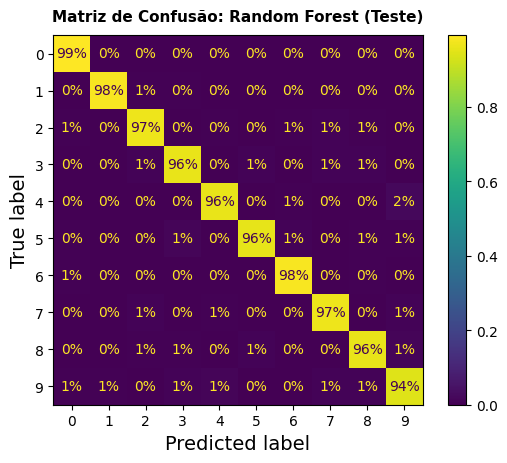

In [ ]:
plt.rc('font', size=10)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_forest,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: Random Forest (Teste)", fontsize=11, fontweight='bold', pad=10)

plt.show()

## **5.4. SVC**

In [ ]:
print("\n" + "="*40)
print("     TESTE: SVC")
print("="*40)

# Predição
y_pred_svc = svc_clf.predict(X_test_scaled)

# Métricas detalhadas por classe (0 a 9)
print(classification_report(y_test, y_pred_svc, digits=4))

# Resumo com agregação macro para multiclasse
print("-" * 40)
print(f"Acurácia:   {accuracy_score(y_test, y_pred_svc):.2%}")
print(f"Precisão:   {precision_score(y_test, y_pred_svc, average='macro', zero_division=0):.2%}")
print(f"Recall:     {recall_score(y_test, y_pred_svc, average='macro'):.2%}")
print(f"F1-Score:   {f1_score(y_test, y_pred_svc, average='macro'):.2%}")
print("-" * 40)


     TESTE: SVC
              precision    recall  f1-score   support

           0     0.9751    0.9913    0.9831      1381
           1     0.9829    0.9848    0.9838      1575
           2     0.9642    0.9635    0.9639      1398
           3     0.9679    0.9503    0.9590      1428
           4     0.9681    0.9560    0.9620      1365
           5     0.9703    0.9557    0.9629      1263
           6     0.9744    0.9702    0.9723      1375
           7     0.9150    0.9740    0.9436      1459
           8     0.9660    0.9560    0.9610      1365
           9     0.9623    0.9367    0.9494      1391

    accuracy                         0.9642     14000
   macro avg     0.9646    0.9638    0.9641     14000
weighted avg     0.9645    0.9642    0.9642     14000

----------------------------------------
Acurácia:   96.42%
Precisão:   96.46%
Recall:     96.38%
F1-Score:   96.41%
----------------------------------------


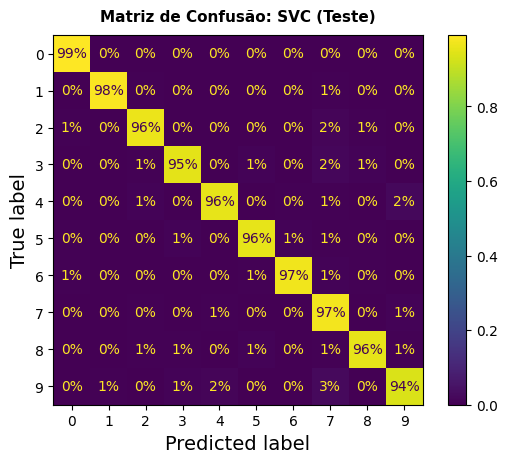

In [ ]:
plt.rc('font', size=10)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svc,
                                        normalize="true", values_format=".0%")

plt.title("Matriz de Confusão: SVC (Teste)", fontsize=11, fontweight='bold', pad=10)

plt.show()

# **EXERCÍCIO 3**

**Dataset:** Wine Recognition Dataset é composto por 178 amostras de vinhos derivados de 3 cultivares diferentes da mesma região da Itália, com 13 constituintes químicos medidos (álcool, ácido málico, cinzas, magnésio, fenóis totais, flavonoides, cor, prolina, etc.).

**Objetivo:** Determinar a qual das 3 cultivares (Class_0, Class_1 ou Class_2) pertence uma garrafa de vinho com base em sua análise físico-química.

**Tipo de Aprendizado:** Aprendizado Supervisionado

**Tipo de Tarefa:** Classificação Multiclasse (3 classes de cultivares)

**Quantidade de entradas e saídas:** MISO (Multiple Inputs, Single Output — 13 atributos contínuos de entrada para 1 rótulo de classe na saída)

**Formato de aprendizado:** Aprendizado em lote (Batch Learning)

**Medida de Desempenho:** Acurácia, Precisão, Recall, F1-Score e Matriz de Confusão

In [ ]:
import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

=== DISTRIBUIÇÃO DAS 3 CLASSES ===
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64

=== EVIDÊNCIA DA DISCREPÂNCIA DE ESCALAS (Min / Max) ===
        alcohol   magnesium      proline  nonflavanoid_phenols
min   11.030000   70.000000   278.000000              0.130000
mean  13.000618   99.741573   746.893258              0.361854
max   14.830000  162.000000  1680.000000              0.660000
